# Assess
Evaluación sobre la partición reservada y dos repositorios fuera del corpus.

In [1]:
import json
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
ROOT = next(folder for folder in (cwd, *cwd.parents)
            if (folder / "data" / "dataset.csv").is_file()
            and (folder / "scripts" / "corpus.py").is_file())
sys.path.insert(0, str(ROOT))

if "show_chart" not in globals():
    def show_chart(name):
        from IPython.display import SVG, display
        display(SVG(filename=str(ROOT / "artifacts" / "charts" / f"{name}.svg")))


In [2]:
from scripts.train import ARTIFACTS
from scripts.demo import evaluate_demo
results = json.loads((ARTIFACTS / "metrics.json").read_text(encoding="utf-8"))
item = results["comparison"][results["selected"]]["test"]
print("Registros de prueba:", item["n"])
print("F1 macro OWASP:", round(item["owasp"]["macro_f1"], 4))
print("Categoría   Precisión   Recall       F1   Soporte    TP    FP    FN    TN")
for key, row in item["owasp"]["per_label"].items():
    print(f"{key:10} {row['precision']:9.3f} {row['recall']:8.3f} {row['f1']:8.3f} "
          f"{row['support']:9} {row['tp']:5} {row['fp']:5} {row['fn']:5} {row['tn']:5}")
print("Matriz binaria [[TN, FP], [FN, TP]]:", item["binary"]["per_label"]["vulnerable"]["matrix"])
print("Errores:", len(item["errors"]))
print("Sin evaluación:", ", ".join(item["unassessed_owasp"]))

Registros de prueba: 120
F1 macro OWASP: 1.0
Categoría   Precisión   Recall       F1   Soporte    TP    FP    FN    TN
A01:2025       1.000    1.000    1.000        12    12     0     0   108
A02:2025       1.000    1.000    1.000        12    12     0     0   108
A04:2025       1.000    1.000    1.000        12    12     0     0   108
A06:2025       1.000    1.000    1.000        12    12     0     0   108
A07:2025       1.000    1.000    1.000        12    12     0     0   108
API1:2023      1.000    1.000    1.000        11    11     0     0   109
API2:2023      1.000    1.000    1.000        11    11     0     0   109
API4:2023      1.000    1.000    1.000        11    11     0     0   109
API8:2023      1.000    1.000    1.000        11    11     0     0   109
Matriz binaria [[TN, FP], [FN, TP]]: [[60, 0], [0, 60]]
Errores: 0
Sin evaluación: A03:2025, A05:2025, A08:2025, A09:2025, A10:2025, API10:2023, API3:2023, API5:2023, API6:2023, API7:2023, API9:2023


In [3]:
demo = evaluate_demo()
for name, row in demo.items():
    print(name, "precisión", round(row["precision"], 3), "recall", round(row["recall"], 3))
    print("Falsos positivos:", row["falsos_positivos"])
    print("Falsos negativos:", row["falsos_negativos"])

VulnMiner · proyecto-reservado
3 microservicios, 8 archivos analizados, 5 hallazgos potenciales (0 pendientes de clasificación)
  documents · documents-api/document-policy.js:1 · A01:2025, API1:2023 · 0.97
  gateway · gateway-api/application.yml:1 · A02:2025, API8:2023 · 0.98
  gateway · gateway-api/application.yml:2 · A06:2025, API4:2023 · 0.97
  identity · identity-api/session_policy.py:3 · A07:2025, API2:2023 · 0.96
  identity · identity-api/session_policy.py:4 · A04:2025 · 0.97
artifacts/demo/reservado/analisis.json
artifacts/demo/reservado/analisis.html
VulnMiner · proyecto-contraste
2 microservicios, 4 archivos analizados, 4 hallazgos potenciales (0 pendientes de clasificación)
  events-api · services/events-api/settings.js:1 · A07:2025, API2:2023 · 0.72
  events-api · services/events-api/settings.js:2 · A06:2025, API4:2023 · 0.90
  ops-api · services/ops-api/application.yml:5 · A07:2025, API2:2023 · 0.97
  ops-api · services/ops-api/application.yml:9 · A02:2025, API8:2023 · 0.98

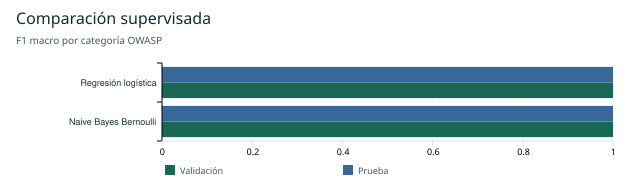

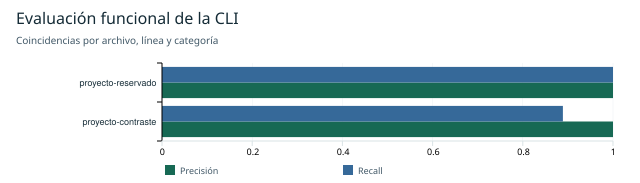

In [4]:
show_chart("comparacion")
show_chart("generalizacion")

La prueba sintética premia el aprendizaje de estados y términos compartidos. En el contraste, el transporte expresado como protocolo produjo un falso negativo en A04. La métrica funcional exige coincidencia de archivo, línea y etiqueta, y la anotación de referencia es manual. Los repositorios son controlados y la demostración con el proyecto del docente queda pendiente.